# pdbKit notebook 1 — a protein: EGFR kinase with the drug erlotinib (PDB 1M17)

**What this notebook shows.** A complete structural look at one drug–target complex, done with pdbKit from Python:

1. load the structure and read what is in it;
2. write the protein in different representations (all-atom, C-alpha, with/without the drug);
3. find where the drug binds — direct atom contacts, the surface it buries, and the Het-PDB Navi contact table;
4. check the backbone geometry (Ramachandran plot);
5. move the drug to the origin (a ready-made docking-box centre);
6. annotate the chain (secondary structure, bonding) and export a FASTA file;
7. compare the crystal structure with the **AlphaFold** prediction, using AlphaFold's own confidence (pLDDT).

**The system.** Erlotinib (Tarceva) is an anticancer drug that blocks the ATP pocket of the epidermal growth factor receptor (EGFR) kinase. Entry 1M17 (Stamos *et al.*, 2002) is the kinase domain with erlotinib bound, solved by X-ray crystallography at 2.6 Å. In the file the drug is the ligand `AQ4`.

**Inputs** are in `data/` next to this notebook, so everything runs offline:
`1M17.cif` (the crystal structure), `1M17_assembly1.dat` (Het-PDB Navi interaction data) and `AF-P00533-F1.cif` (the AlphaFold DB model of full-length human EGFR).
Files written by the notebook go to `output/protein/`.

> Every function used here is also a `pdbkit` terminal command — the equivalent command is given in each section.

## 0. Setup

`import pdbkit as pk` gives access to every feature. pandas is used only to display tables, matplotlib only for the two figures. The small `style()` helper gives the figures a quiet, readable look (thin marks, light grid, muted axes).

In [1]:
import warnings
warnings.filterwarnings("ignore", message="You may be importing Biopython")   # harmless environment warning in biopyc

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdbkit as pk

DATA = Path("data")
OUT = Path("output/protein")
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"

def style(ax, title):
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.grid(color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(MUTED); ax.yaxis.label.set_color(MUTED)

print("pdbKit", pk.__version__)

pdbKit 1.0.0


## 1. Load the structure and look inside

`pk.load()` reads PDB or mmCIF (gzipped too), or downloads by ID (`pk.load("1M17")`). It returns a Biopython `Structure`, so anything Biopython can do works on it as well.

On loading, pdbKit sorts every residue into **polymer**, **ligand** or **water**. That classification is what "heteroatoms" means in all the selection options below.

*Terminal:* `pdbkit info data/1M17.cif`

In [2]:
s = pk.load(DATA / "1M17.cif")
info = pk.summary(s)
exp = pk.experiment(s)
pd.Series({**info, **{f"exp_{k}": v for k, v in exp.items() if k != "id"}}).to_frame("value")

,value
id,1M17
models,1
chains,[A]
polymer_residues,312
ligand_residues,1
water_molecules,20
atoms,2560
hetatm_atoms,49
has_altlocs,True
has_insertion_codes,False


**Reading the output.** One protein chain (A) with 312 modelled residues, one ligand (`AQ4` = erlotinib) and 20 water molecules — 2,560 atoms in total. Two flags matter for later steps:

* `has_altlocs = True` — some atoms were modelled in two alternative positions. pdbKit uses the highest-occupancy position for geometry (centre of mass, distances) and keeps all positions when writing files.
* `has_sequence_gaps = True` — part of the chain was not visible in the electron density. The next cell shows where.

The experiment fields come from the file header: X-ray, 2.6 Å resolution, R-work 0.251 / R-free 0.295.

In [3]:
print("Chain breaks:")
display(pk.to_dataframe(pk.gaps(s)))

seqres = pk.sequences(s, "seqres")["A"]      # the sequence that was crystallised
atom = pk.sequences(s, "atom")["A"]          # the residues that have coordinates
print(f"deposited sequence: {len(seqres)} residues, modelled: {len(atom)} residues, "
      f"unmodelled: {len(seqres) - len(atom)}")

Chain breaks:


,model,chain,from,to,type,distance
0,1,A,A:HIS:964,A:LEU:977,distance,7.19


deposited sequence: 333 residues, modelled: 312 residues, unmodelled: 21


**Reading the output.** One break, between His964 and Leu977: residues 965–976 lie in a flexible loop and are absent from the model. `gaps()` detects a break from the missing peptide bond (the C–N distance), so a slightly stretched but intact bond is not reported.

The two sequences differ in length because the crystallised construct (333 residues, starting with the `GSHM` left over from the expression tag) is longer than what could be modelled (312): 21 residues — the tag, the flexible loop and chain ends — have no coordinates.

## 2. Write the protein in different representations

`pk.split_chains()` produces one structure per chain; `pk.extract()` one structure for any selection. The options are the same everywhere:

| option | meaning |
|---|---|
| `atoms="all"` / `"ca"` / `"backbone"` / `"trace"` | which atoms of the **polymer** to keep |
| `het="none"` / `"all"` / `["AQ4", ...]` | which **ligands** to keep (always whole) |
| `water=True/False` | keep water |

`pk.save()` picks the format from the file extension; every file opens in PyMOL, Mol*, ChimeraX.

*Terminal:* `pdbkit split data/1M17.cif --atoms ca --het AQ4 -d output/protein`

In [4]:
variants = {
    "all_atom":             dict(atoms="all", het="none", water=False),
    "ca_only":              dict(atoms="ca",  het="none", water=False),
    "ca_with_erlotinib":    dict(atoms="ca",  het=["AQ4"], water=False),
    "all_atom_with_all_het": dict(atoms="all", het="all",  water=True),
}
rows = []
for name, sel in variants.items():
    part = pk.split_chains(s, **sel)["A"]
    path = pk.save(part, OUT / f"1M17_A_{name}.pdb")
    n_lig = sum(1 for r in part.get_residues() if pk.residue_kind(r) == "ligand")
    rows.append({"file": Path(path).name, "atoms": len(list(part.get_atoms())), "ligand residues": n_lig})
pd.DataFrame(rows)

,file,atoms,ligand residues
0,1M17_A_all_atom.pdb,2497,0
1,1M17_A_ca_only.pdb,312,0
2,1M17_A_ca_with_erlotinib.pdb,341,1
3,1M17_A_all_atom_with_all_het.pdb,2546,1


**Reading the output.** The C-alpha file has exactly 312 atoms — one per modelled residue. Adding erlotinib adds its 29 atoms as a whole molecule (the drug has no "C-alpha"; ligands are never reduced). The last file contains everything: protein, drug and the 20 waters.

## 3. Where does erlotinib bind?

### 3a. Direct contacts

`pk.contacts(structure, target, cutoff)` lists every residue with any atom within `cutoff` Å of the target (here the drug), with the closest distance. All alternate positions are considered.

*Terminal:* `pdbkit contacts data/1M17.cif -t AQ4 --cutoff 4.0`

In [5]:
contacts = pk.to_dataframe(pk.contacts(s, "AQ4", 4.0))
contacts

,target,residue,min_distance
0,A:AQ4:999,A:LEU:694,3.269
1,A:AQ4:999,A:ALA:719,3.307
2,A:AQ4:999,A:LYS:721,3.700
3,A:AQ4:999,A:GLU:738,3.806
4,A:AQ4:999,A:LEU:764,3.431
5,A:AQ4:999,A:THR:766,3.406
6,A:AQ4:999,A:GLN:767,3.146
7,A:AQ4:999,A:LEU:768,3.496
8,A:AQ4:999,A:MET:769,2.699
9,A:AQ4:999,A:PRO:770,3.107


In [6]:
# The single closest contact: which atoms?
chain = s[0]["A"]
drug = next(r for r in chain if r.get_resname() == "AQ4")
met769 = chain[769]
d, a_drug, a_met = min((float(np.linalg.norm(a.coord - b.coord)), a.get_id(), b.get_id())
                       for a in drug for b in met769)
print(f"closest contact: erlotinib {a_drug} - Met769 {a_met} = {d:.2f} A")

closest contact: erlotinib N2 - Met769 N = 2.70 A


**Reading the output.** Fifteen residues line the pocket within 4 Å. The shortest contact, **2.70 Å from the drug's quinazoline nitrogen (atom `N2` in this entry) to the backbone N of Met769**, is the hydrogen bond to the kinase *hinge* — the interaction that anchors almost every ATP-competitive kinase inhibitor. The other residues are the classic ATP-pocket walls: Leu694 and Val702 (glycine-rich loop side), Ala719 and Lys721 (β3 strand), Thr766 (the "gatekeeper"), Leu820 (floor) and Asp831 (the DFG motif).

### 3b. Surface buried by the drug

`pk.sasa()` computes the solvent-accessible surface area with the Shrake–Rupley algorithm (no external program needed). Computing it **without** and **with** the ligand, and subtracting, shows which residues the drug covers.

In [7]:
apo = pk.to_dataframe(pk.sasa(s, include_het=False))    # protein alone
holo = pk.to_dataframe(pk.sasa(s, include_het=True))    # protein + erlotinib
sasa = apo.merge(holo, on="residue", suffixes=("_free", "_with_drug"))
sasa["buried_by_drug"] = (sasa["sasa_free"] - sasa["sasa_with_drug"]).round(1)
buried = sasa[sasa.buried_by_drug > 0].sort_values("buried_by_drug", ascending=False)
print(f"protein surface buried by erlotinib: {buried.buried_by_drug.sum():.0f} A^2 over {len(buried)} residues")
buried.head(10)[["residue", "sasa_free", "sasa_with_drug", "buried_by_drug"]]

protein surface buried by erlotinib: 332 A^2 over 20 residues


,residue,sasa_free,sasa_with_drug,buried_by_drug
22,A:LEU:694,99.75,41.96,57.8
148,A:LEU:820,41.06,4.83,36.2
30,A:VAL:702,35.02,6.04,29.0
49,A:LYS:721,59.76,33.77,26.0
100,A:GLY:772,25.36,1.21,24.2
98,A:PRO:770,81.11,59.68,21.4
94,A:THR:766,26.53,5.77,20.8
159,A:ASP:831,57.08,40.85,16.2
47,A:ALA:719,14.36,0.00,14.4
158,A:THR:830,15.14,1.07,14.1


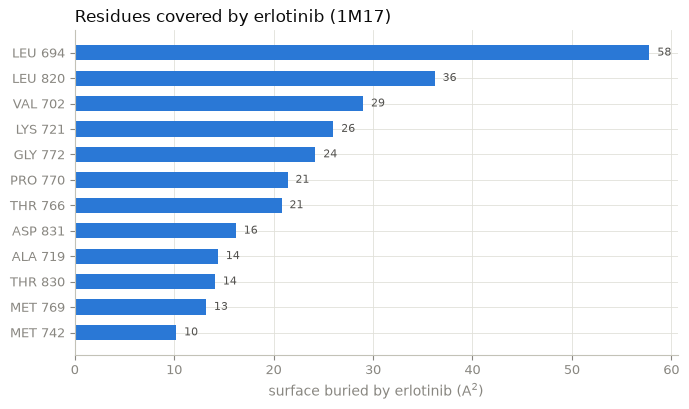

In [8]:
top = buried.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
labels = top.residue.str.split(":").str[1] + " " + top.residue.str.split(":").str[2]     # "A:LEU:694" -> "LEU 694"
ax.barh(labels, top.buried_by_drug, color=BLUE, height=0.6)
for y, v in enumerate(top.buried_by_drug):
    ax.text(v + 0.8, y, f"{v:.0f}", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("surface buried by erlotinib (A$^2$)")
style(ax, "Residues covered by erlotinib (1M17)")
plt.tight_layout(); plt.show()

**Reading the output.** Erlotinib buries about 330 Å² of protein surface. Leu694 contributes the most, followed by Leu820, Val702 and Lys721 — the hydrophobic sandwich above and below the flat quinazoline ring. Val702 does not appear in the 4 Å contact list but is buried: surface area captures residues that shield the drug without touching it closely.

### 3c. Het-PDB Navi contact table

Het-PDB Navi (Nagahama Institute of Bio-Science) publishes pre-computed protein–ligand contacts for every PDB entry. `pk.hetnavi.interactions()` downloads (or, as here, reads a saved copy) and writes one CSV per ligand.

> The original parser silently dropped contact lines that lack a hydrogen-bond count — for 1M17 it produced an empty table. pdbKit keeps them (`num_hbonds` is then empty).

*Terminal:* `pdbkit hetnavi 1M17 -d output/protein/hetnavi`

In [9]:
records, paths = pk.hetnavi.interactions("1M17", dat_file=str(DATA / "1M17_assembly1.dat"),
                                         outdir=str(OUT / "hetnavi"))
navi = pk.to_dataframe(pk.hetnavi.het_contacts_table(records))
navi = navi[["heteroatom", "res_end", "res_name", "contact_type", "num_contacts"]].rename(
    columns={"res_end": "residue_number"})
print([Path(p).name for p in paths])
navi

['1M17_AQ4_999_A_interaction.csv', '1M17_all_het_interactions.csv', '1M17_disorder.csv']


,heteroatom,residue_number,res_name,contact_type,num_contacts
0,AQ4:999:A,694,LEU,A,7
1,AQ4:999:A,719,ALA,S,3
2,AQ4:999:A,721,LYS,S,7
3,AQ4:999:A,738,GLU,S,1
4,AQ4:999:A,764,LEU,A,3
5,AQ4:999:A,766,THR,S,3
6,AQ4:999:A,767,GLN,B,1
7,AQ4:999:A,768,LEU,A,6
8,AQ4:999:A,769,MET,A,13
9,AQ4:999:A,770,PRO,B,2


In [10]:
ours = {int(r.split(":")[2]) for r in contacts.residue}
theirs = {int(n) for n in navi.residue_number}
print("in both lists:        ", sorted(ours & theirs))
print("only pdbKit (4.0 A):  ", sorted(ours - theirs))
print("only Het-PDB Navi:    ", sorted(theirs - ours))

in both lists:         [694, 719, 721, 738, 764, 766, 767, 768, 769, 770, 771, 772, 820, 830, 831]
only pdbKit (4.0 A):   []
only Het-PDB Navi:     []


**Reading the output.** The two independent methods agree exactly: the same 15 residues. Het-PDB Navi also counts atom contacts per residue (`num_contacts`) and says which part of the residue makes them (`contact_type`: `S` side chain, `B` backbone, `A` both). Met769 again stands out with 13 contacts, and the hinge residues 767–772 contact the drug through their backbone (`B`), as expected for the hinge region.

## 4. Backbone geometry: Ramachandran plot

`pk.torsions()` returns φ/ψ for every residue. Angles are only computed across real peptide bonds, so the residues on either side of the 965–976 gap get `None` rather than a meaningless angle.

*Terminal:* `pdbkit torsion data/1M17.cif`

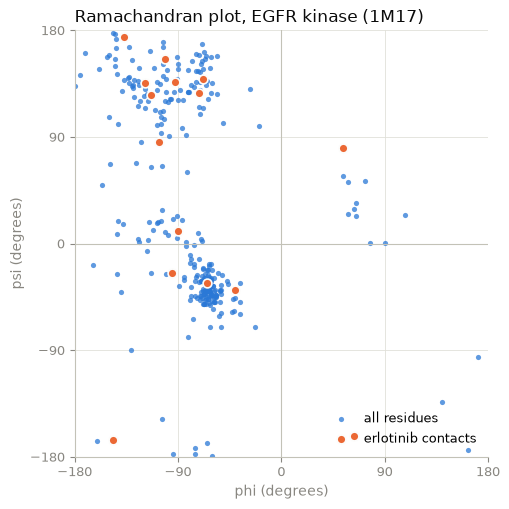

308 residues with both angles; helical region 52%, beta region 37%, positive phi 5%


In [11]:
tor = pk.to_dataframe(pk.torsions(s)).dropna()
site = set(contacts.residue)
is_site = tor.residue.isin(site)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(tor.phi[~is_site], tor.psi[~is_site], s=14, color=BLUE, alpha=0.75, linewidths=0, label="all residues")
ax.scatter(tor.phi[is_site], tor.psi[is_site], s=40, color=ORANGE, edgecolors="#fcfcfb", linewidths=1.2,
           label="erlotinib contacts")
ax.set_xlim(-180, 180); ax.set_ylim(-180, 180)
ax.set_xticks(range(-180, 181, 90)); ax.set_yticks(range(-180, 181, 90))
ax.set_xlabel("phi (degrees)"); ax.set_ylabel("psi (degrees)")
ax.axhline(0, color="#c3c2b7", lw=0.8); ax.axvline(0, color="#c3c2b7", lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="lower right")
style(ax, "Ramachandran plot, EGFR kinase (1M17)")
plt.tight_layout(); plt.show()

helix = ((tor.phi.between(-160, -20)) & (tor.psi.between(-120, 50))).mean()
sheet = ((tor.phi.between(-180, -40)) & (tor.psi.between(90, 180))).mean()
print(f"{len(tor)} residues with both angles; helical region {helix:.0%}, beta region {sheet:.0%}, "
      f"positive phi {(tor.phi > 0).mean():.0%}")

**Reading the output.** The points fall into the two expected populations — the α-helical region (φ ≈ −60°, ψ ≈ −45°) and the β region (φ ≈ −120°, ψ ≈ +130°) — with a small number of positive-φ residues (mostly glycines, which are allowed there). The drug-contact residues (orange) sit in normal regions: the binding site is not strained.

## 5. Put the drug at the origin

Docking programs need the centre of the pocket. `pk.center()` moves the centre of mass of a **selection** to (0, 0, 0). With `apply_to="all"` the **whole** structure moves with it — the protein keeps its shape, only its position changes.

The centre of mass uses one position per atom (the highest-occupancy alternate location) and element masses.

*Terminal:* `pdbkit center data/1M17.cif --resnames AQ4 --keep-all -o output/protein/1M17_drug_at_origin.cif`

In [12]:
moved, com_before = pk.center(s, resnames=["AQ4"], apply_to="all")
pk.save(moved, OUT / "1M17_drug_at_origin.cif")

print("drug centre of mass before:", np.round(com_before, 3))
print("drug centre of mass after: ", np.round(pk.center_of_mass(moved, resnames=["AQ4"]), 4))
print("protein centre of mass after:", np.round(pk.center_of_mass(moved, het="none", water=False), 2))

# the move is a rigid translation: every atom shifted by the same vector
x0 = pk.geometry.coordinates(s); x1 = pk.geometry.coordinates(moved)
print("max deviation from a pure translation:", float(np.abs((x1 - x0) - (x1 - x0)[0]).max()), "A")

drug centre of mass before: [21.857  0.26  52.761]
drug centre of mass after:  [-0.  0.  0.]


protein centre of mass after: [1.34 9.72 6.66]
max deviation from a pure translation: 3.552713678800501e-15 A


**Reading the output.** After the move the drug's centre of mass is at the origin, and every atom — including the 14 atoms modelled in two alternative positions — moved by exactly the same vector (maximum deviation ≈ 0): the complex is unchanged, only placed differently. The protein's own centre of mass is now about 12 Å from the origin, because the ATP pocket lies off-centre in the kinase.

> Writing this notebook exposed a bug that is now fixed in pdbKit: after copying a structure, atoms with alternate positions still *read* their coordinates from the original. Files written were always correct; the in-memory check above failed until the fix.

## 6. Chain annotation and FASTA

`pk.domains.annotate()` builds the per-chain table of the integrated *mmcif_domain_family* tool: EC number, UniProt accession, secondary-structure order and ranges, ligands and their bonding partners. `skip_lookups=True` keeps it offline (live mode adds UniProt family/domain and KEGG enzyme names).

*Terminal:* `pdbkit domains data/1M17.cif -q -d output/protein`

In [13]:
ann = pk.domains.annotate(s, skip_lookups=True)[0]
for k in ("Entity_Description", "EC_Number", "EC_Type", "UniProt_Accession", "Heteroatoms_In_Chain",
          "Heteroatom_Bonding_Partners"):
    print(f"{k:28s} {ann[k]}")
order = ann["Secondary_Structure_Order"].split("-")
print(f"{'Secondary structure':28s} {len(order)} elements: "
      f"{order.count('Helix')} helices, {order.count('Sheet')} strands, {order.count('Turn')} turns, {order.count('Coil')} coil segments")
print("first elements:", ann["Secondary_Structure_Residue_Ranges"][:120], "...")

Entity_Description           epidermal growth factor receptor
EC_Number                    2.7.1.112
EC_Type                      Transferases
UniProt_Accession            P00533
Heteroatoms_In_Chain         AQ4999
Heteroatom_Bonding_Partners  AQ4999 -> (no _struct_conn record found)
Secondary structure          47 elements: 15 helices, 11 strands, 0 turns, 21 coil segments
first elements: Coil:672-683; Helix:684-686; Coil:687-687; Sheet:688-695; Coil:696-700; Sheet:701-707; Coil:708-715; Sheet:716-722; Coil ...


In [14]:
path = pk.write_fasta(s, OUT / "1M17.fasta")
print(open(path).read())

>1M17_A mol:protein length:333 source:seqres epidermal growth factor receptor
GSHMASGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELRE
ATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNI
GSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEY
HAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEK
GERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHL
PSPTDSNFYRALMDEEDMDDVVDADEYLIPQQG



**Reading the output.** The file records EC 2.7.1.112 — the EC number protein-tyrosine kinases had in 2002; it has since been transferred to EC 2.7.10.1 (receptor protein-tyrosine kinase). The class is "Transferases" and the UniProt entry is P00533. Erlotinib has no covalent or metal bond to the protein (it binds through contacts only), so its bonding-partner field says so. The secondary-structure order describes the kinase fold as it is annotated in the file.

The FASTA record contains the full deposited sequence (333 residues), with the molecule type, length and the source of the sequence (`seqres` = deposited sequence) in the header.

## 7. Crystal structure versus the AlphaFold prediction

AlphaFold DB has a model of full-length EGFR (1,210 residues). Two things are needed to compare it with the crystal:

1. **Residue numbering.** The crystal uses the numbering of the mature protein; UniProt/AlphaFold count from the start of the signal peptide. Matching the crystal's modelled sequence inside the AlphaFold sequence gives the offset.
2. **What to superpose on.** AlphaFold stores its per-residue confidence, **pLDDT (0–100)**, in the B-factor column. Superposing on the confidently predicted residues (pLDDT ≥ 90) avoids letting flexible parts dominate.

*Terminal (download):* `pdbkit fetch P00533 --pae` — here the saved copy in `data/` is used.

In [15]:
af = pk.load(DATA / "AF-P00533-F1.cif")
af_seq = pk.sequences(af)["A"]
crystal_seq = pk.sequences(s, "atom")["A"]
offset = af_seq.find(crystal_seq[:20]) + 1 - s[0]["A"].child_list[0].id[1]
print(f"AlphaFold model: {len(af_seq)} residues, mean pLDDT {np.mean([r['CA'].bfactor for r in af[0]['A']]):.1f}")
print(f"numbering offset: crystal residue n = AlphaFold residue n + {offset}  (Met769 -> Met{769 + offset})")
assert af[0]["A"][769 + offset].get_resname() == "MET"

AlphaFold model: 1210 residues, mean pLDDT 75.9
numbering offset: crystal residue n = AlphaFold residue n + 24  (Met769 -> Met793)


In [16]:
from Bio.PDB import Superimposer

X, A = s[0]["A"], af[0]["A"]
pairs = [(r["CA"], A[r.id[1] + offset]["CA"]) for r in X
         if pk.residue_kind(r) == "polymer" and "CA" in r and (r.id[1] + offset) in A]
core = [p for p in pairs if p[1].bfactor >= 90]

sup = Superimposer()
sup.set_atoms([p[0] for p in core], [p[1] for p in core])     # fit AlphaFold onto the crystal
rot, tran = sup.rotran
dev = pd.DataFrame([{"residue": x.get_parent().id[1],
                     "pLDDT": a.bfactor,
                     "deviation_A": float(np.linalg.norm(x.coord - (a.coord @ rot + tran)))} for x, a in pairs])

print(f"superposed on {len(core)} confident residues (pLDDT >= 90): RMSD {sup.rms:.2f} A")
print(f"all {len(dev)} residues after this fit: median deviation {dev.deviation_A.median():.2f} A, "
      f"{(dev.deviation_A < 2).mean():.0%} within 2 A")
site_nums = sorted(int(r.split(":")[2]) for r in contacts.residue)
site_dev = dev[dev.residue.isin(site_nums)]
print(f"erlotinib-site residues: mean deviation {site_dev.deviation_A.mean():.2f} A, mean pLDDT {site_dev.pLDDT.mean():.1f}")
site_dev.round(2).set_index("residue").T

superposed on 123 confident residues (pLDDT >= 90): RMSD 0.36 A
all 312 residues after this fit: median deviation 0.60 A, 74% within 2 A
erlotinib-site residues: mean deviation 0.91 A, mean pLDDT 84.0


residue,694,719,721,738,764,766,767,768,769,770,771,772,820,830,831
pLDDT,79.69,89.44,86.38,67.44,85.56,88.38,86.00,85.44,86.75,77.44,84.50,85.12,92.62,87.88,76.75
deviation_A,0.80,1.03,1.21,3.32,1.40,1.07,0.73,0.99,0.83,0.61,0.45,0.46,0.09,0.33,0.41


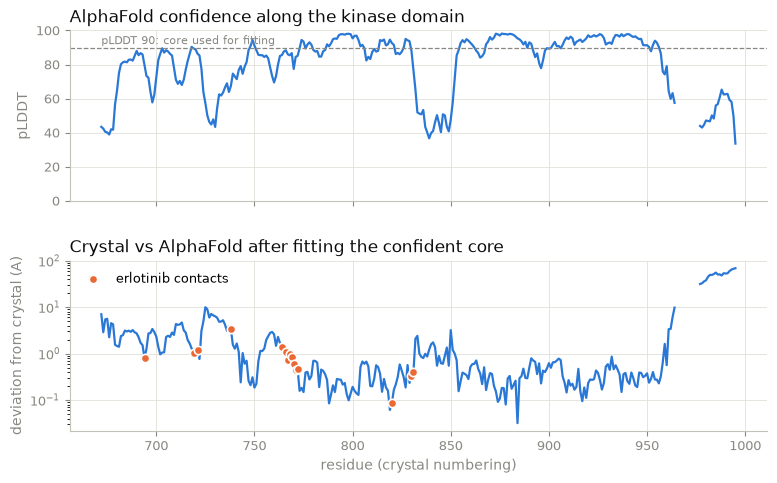

In [17]:
# reindex on every residue number so the unmodelled loop (965-976) shows as a break, not a straight line
full = dev.set_index("residue").reindex(range(dev.residue.min(), dev.residue.max() + 1))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"hspace": 0.35})
ax1.plot(full.index, full.pLDDT, color=BLUE, lw=1.6)
ax1.axhline(90, color=MUTED, lw=0.9, ls="--")
ax1.text(dev.residue.min(), 92, "pLDDT 90: core used for fitting", fontsize=8, color=MUTED)
ax1.set_ylabel("pLDDT"); ax1.set_ylim(0, 100)
style(ax1, "AlphaFold confidence along the kinase domain")
ax2.plot(full.index, full.deviation_A, color=BLUE, lw=1.6)
ax2.scatter(site_dev.residue, site_dev.deviation_A, s=36, color=ORANGE, edgecolors="#fcfcfb", linewidths=1.2,
            zorder=3, label="erlotinib contacts")
ax2.set_yscale("log"); ax2.set_ylabel("deviation from crystal (A)"); ax2.set_xlabel("residue (crystal numbering)")
ax2.legend(frameon=False, fontsize=9, loc="upper left")
style(ax2, "Crystal vs AlphaFold after fitting the confident core")
plt.show()

**Reading the output.**

* The confident core superposes with an RMSD of about **0.4 Å** — for these residues the prediction is as accurate as the crystal structure itself.
* The erlotinib pocket agrees closely (mean deviation about 0.9 Å), even though the AlphaFold model contains no drug.
* Two regions differ, and both are known to be mobile: the **αC-helix region (≈ residues 723–738)** — its position switches between the active and inactive kinase states, so the model and this inhibitor-bound crystal need not agree (Glu738 of the pocket sits there) — and the **C-terminal tail after residue 977**, where pLDDT drops sharply and the deviation reaches tens of ångströms. Low pLDDT flags exactly the parts that should not be trusted.

These differences are a property of the protein, not of the method — the plot of pLDDT (top) predicts where the deviation (bottom) will be large.

## Summary

| Question | pdbKit function | Result for 1M17 |
|---|---|---|
| What is in the file? | `summary`, `experiment`, `gaps` | 1 chain, 312 of 333 residues modelled, erlotinib, 20 waters; loop 965–976 missing |
| How to export representations? | `split_chains`, `extract`, `save` | all-atom / C-alpha / ± drug / ± water files |
| Where does the drug bind? | `contacts`, `sasa`, `hetnavi` | 15 residues ≤ 4 Å (identical in Het-PDB Navi); hinge H-bond to Met769 (2.70 Å); ≈ 330 Å² buried |
| Is the geometry normal? | `torsions` | standard α/β populations; pocket unstrained |
| Pocket centre for docking? | `center(..., apply_to="all")` | drug COM moved to the origin, rigid translation |
| Annotation / sequence? | `domains.annotate`, `write_fasta` | EC 2.7.1.112 (now 2.7.10.1), UniProt P00533; FASTA written |
| Does AlphaFold agree? | `load`, `sequences`, B-factor = pLDDT | core RMSD ≈ 0.4 Å; differences only in αC region and C-terminal tail |

All files written by this notebook are in `output/protein/`.